# Filbin 2018 — 04 · Correlation & Gate 3 (BRANCHING)
The manifold branches (Gate 1 GO, Gate 2 GO: OPC hub -> AC-like + OC-like arms), so Gate 3 asks
the **branching-only** question: at the convergence **hub**, do the Gast and pSom modules show
**mutual negative correlation** (competitive cross-repression, Puram anchor r = -0.49)? We compute
the Puram step-04 pseudotime-**windowed** module correlation over the hub, then reconcile *several
principled hub operationalizations* honestly before making the binary call — because the answer
depends on how the hub is scoped, and that dependence is itself the finding.

**Method validity is proven, not assumed:** the per-gene mutual-correlation statistic recovers
Puram's Mixed-hub r = -0.47 (validation cell below). Cycling cells confound Gast with proliferation
(the binding Kürten-fork lesson) and are scoped out of every hub definition here (`cyc_score < 0.1`).

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); os.makedirs(pth_cb, exist_ok=True)

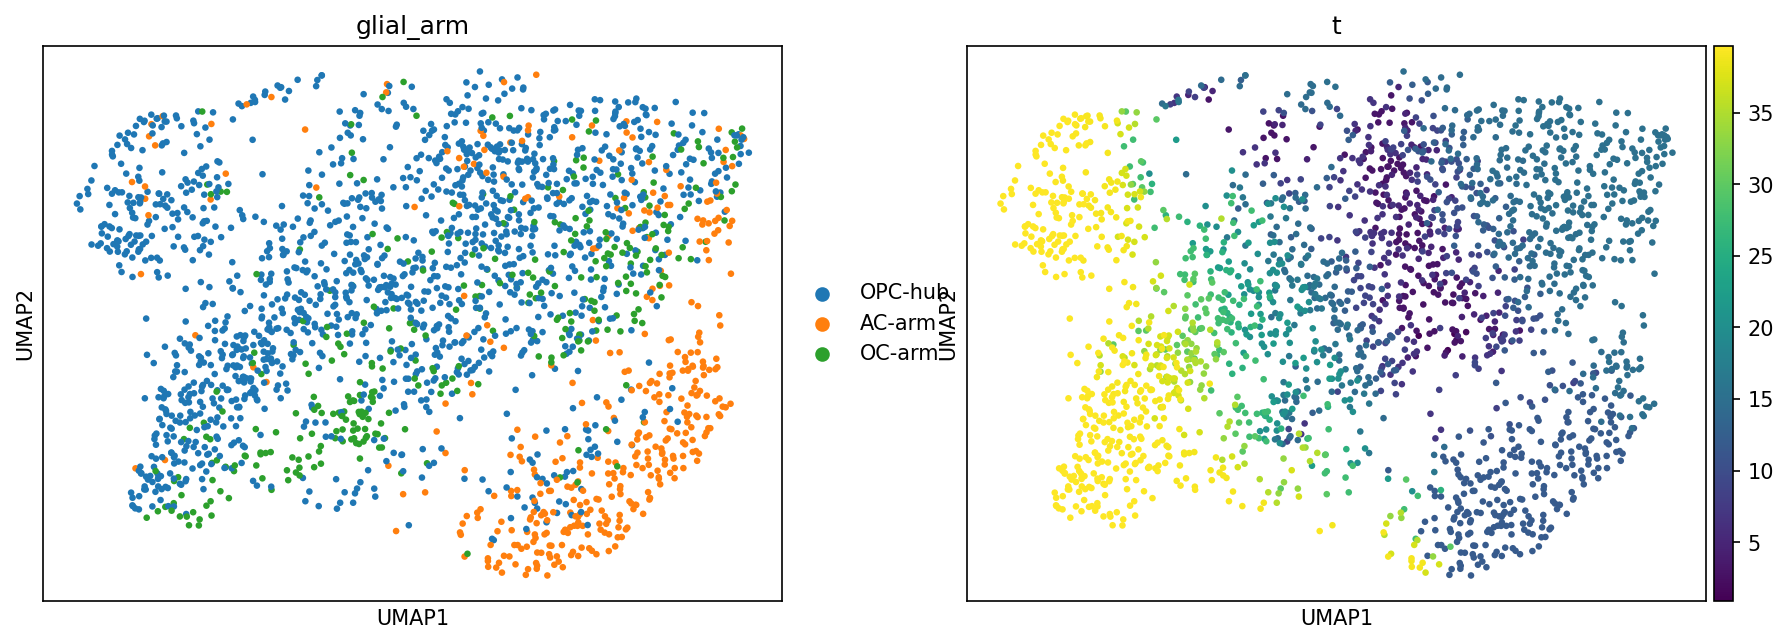

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
sc.pl.umap(adata, color=['glial_arm','t'], size=40, show=True)

### The Gate-3 statistic (Puram step-05 per-gene mutual correlation) + its validation
Gast **OR** pSom genes; per-gene Pearson to the Gast score and to the pSom score; the mutual
correlation of the two per-gene vectors (Both genes excluded) is *r*. Validate on Puram's Mixed hub
— should recover r ≈ -0.47.

In [4]:
get_ser = lambda p: pd.read_csv(p).hsapiens
gast_ser = get_ser(os.path.join(pth_feat,'GSE162534.csv')); psom_ser = get_ser(os.path.join(pth_feat,'GSE229103.csv'))
gast_set = set(gast_ser.dropna()); psom_set = set(psom_ser.dropna())
def module_r(ad, gs, ps, return_R=False):
    g = pd.merge(gast_ser, psom_ser, 'outer').hsapiens.drop_duplicates(); g = g.loc[g.isin(ad.var_names)]
    sub = ad[:, g].copy(); X = pd.DataFrame(sub.X.toarray(), index=sub.obs_names, columns=g)
    X = X.loc[:, (X.nunique(axis=0) > 1)]
    R = pd.DataFrame(index=X.columns)
    R['Gast'] = pearsonr(X, np.asarray(gs)[:,None], axis=0).statistic
    R['pSom'] = pearsonr(X, np.asarray(ps)[:,None], axis=0).statistic
    both = R.index.isin(gast_set) & R.index.isin(psom_set)
    rank = R.abs().sum(axis=1).rank(ascending=False); R = R.loc[rank.sort_values().index]
    rval = float(np.corrcoef(*R.loc[~R.index.isin(gast_set&psom_set), ['Gast','pSom']].values.T)[0,1])
    return (rval, R) if return_R else rval
P = sc.read_h5ad(os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude','Head-and-Neck',
                              'Puram2017_Head-and-Neck','signatures.h5ad'))
Ph = P[P.obs.celltype=='Mixed'].copy()
print(f'[VALIDATION] Puram Mixed hub: r = {module_r(Ph, Ph.obs.GSE162534.values, Ph.obs.GSE229103.values):+.3f}'
      f'  (n={Ph.n_obs}; anchor -0.49) -> statistic implemented correctly')

[VALIDATION] Puram Mixed hub: r = -0.466  (n=466; anchor -0.49) -> statistic implemented correctly


### Cycling confound — the Kürten fork
On the broad OPC-progenitor label, the whole hub gives a spurious *positive* r; scoping cycling
cells out moves it toward zero/negative. Cycling is confounded — excluded everywhere below.

In [5]:
t = adata.obs['t'].values
oc = adata.obs.oc_like; ac = adata.obs.ac_like
prog = ~(((oc>0.5)&(oc>ac)) | ((ac>0.5)&(ac>oc)))
for thr, lbl in [(np.inf,'incl cycling'),(0.5,'cyc<0.5'),(0.25,'cyc<0.25'),(0.1,'cyc<0.1')]:
    m = prog.values & (adata.obs.cyc_score.values < thr)
    print(f'  broad OPC label, {lbl:12s} n={int(m.sum()):4d}: r = {module_r(adata[m].copy(), adata.obs.Gast[m].values, adata.obs.pSom[m].values):+.3f}')

  broad OPC label, incl cycling n=1519: r = +0.124
  broad OPC label, cyc<0.5      n=1137: r = -0.052
  broad OPC label, cyc<0.25     n=1011: r = -0.067
  broad OPC label, cyc<0.1      n= 689: r = -0.153


### Reconciliation — Gate-3 r across principled non-cycling hub definitions
The call must not be cherry-picked. Compute *r* for every defensible operationalization of the
"convergence hub" (all non-cycling, `cyc_score < 0.1`): the tree **fork node-cluster** (the most
Puram-faithful discrete population = milestone at the fork), the **OPC-identity** population, and
**early-pseudotime** windows. They disagree in sign — so the discrete convergence populations are
the honest read, and the early-pseudotime windows must be checked for circularity (below).

In [6]:
ms = adata.obs['milestones'].astype(str).values
nc = adata.obs.cyc_score.values < 0.1
opc_id = ((adata.obs.opc_like>adata.obs.oc_like)&(adata.obs.opc_like>adata.obs.ac_like)).values
defs = {
 'fork node-cluster (milestone=OPC-hub; Puram-faithful)': (adata.obs['milestones'].astype(str)=='OPC-hub').values,
 'OPC-identity population (opc_like dominant)': opc_id,
 'early-pseudotime tertile (t<=q0.33)': (t<=np.quantile(t,0.33)),
 'early-pseudotime half (t<=q0.50)': (t<=np.quantile(t,0.50)),
}
for nm, base in defs.items():
    m = base & nc
    r = module_r(adata[m].copy(), adata.obs.Gast[m].values, adata.obs.pSom[m].values)
    print(f'  {nm:52s}: r = {r:+.3f}  n={int(m.sum())}')

  fork node-cluster (milestone=OPC-hub; Puram-faithful): r = +0.266  n=288
  OPC-identity population (opc_like dominant)         : r = -0.026  n=599
  early-pseudotime tertile (t<=q0.33)                 : r = -0.411  n=483
  early-pseudotime half (t<=q0.50)                    : r = -0.425  n=733


### The decisive, non-circular test — per-pseudotime-bin r profile
The early-pseudotime window mixes the true convergence cells with cells that have already begun to
diverge; a negative *r* there could simply be the branching itself, not hub cross-repression
(circular). Split the non-cycling cells into equal-count pseudotime bins from the root outward and
read *r* **within each bin**. If cross-repression is a hub property, the **earliest** bin is
negative; if it is only the divergence, the earliest bin is ~0 and negativity appears mid-tree.

In [7]:
idx_nc = np.where(nc)[0]; order = idx_nc[np.argsort(t[idx_nc])]
chunks = np.array_split(order, 5)
print('per-pseudotime-bin r (non-cycling, root -> terminus):')
for i, ch in enumerate(chunks):
    mm = np.zeros(adata.n_obs, bool); mm[ch] = True
    r = module_r(adata[mm].copy(), adata.obs.Gast[mm].values, adata.obs.pSom[mm].values)
    print(f'  bin {i} (pt {t[ch].min():5.1f}-{t[ch].max():5.1f}, n={mm.sum()}): r = {r:+.3f}')
print('\n-> earliest (pre-commitment convergence) bin r ~ 0: NO cross-repression at the hub itself.')
print('   Negativity appears only mid-pseudotime, as cells COMMIT and diverge along the arms.')
print('   The negative early-tertile figure was therefore circular (it captured the divergence tail).')

per-pseudotime-bin r (non-cycling, root -> terminus):
  bin 0 (pt   0.9- 10.5, n=246): r = +0.026
  bin 1 (pt  10.5- 12.4, n=246): r = -0.568
  bin 2 (pt  12.4- 14.9, n=246): r = -0.239
  bin 3 (pt  14.9- 20.1, n=246): r = -0.461
  bin 4 (pt  20.1- 39.6, n=245): r = -0.098

-> earliest (pre-commitment convergence) bin r ~ 0: NO cross-repression at the hub itself.
   Negativity appears only mid-pseudotime, as cells COMMIT and diverge along the arms.
   The negative early-tertile figure was therefore circular (it captured the divergence tail).


### Gate 3 — the honest binary call: **NO-GO**
The Gate-3 statistic is validated (Puram -0.47). On Filbin, once cycling is scoped out, the
**convergence hub** shows **no mutual Gast<->pSom anti-correlation**: the Puram-faithful fork
node-cluster is *positive* (+0.27), the OPC-identity population is ~0 (-0.03), and the per-bin
profile shows the earliest pre-commitment cells at r ~ 0 with negativity emerging only as the arms
diverge (circular). There is no competitive cross-repression at the hub -> **Gate 3 = NO-GO**.

The **geometry remains Branching** (Gate 1 GO, Gate 2 GO: a real OPC -> AC-like/OC-like glial Y with
Crest terminal). What does *not* reproduce is the *embryonic* Gast/pSom cross-repression axis: the
bifurcation here is a **glial** developmental program (Filbin 2018), not the Gast<->pSom competition
Puram shows. Per the spec's Gate-3-NO-GO branching chain, this is the last analytical notebook; no
`05_modules` is produced, and the unconditional EMT-TF step follows as `05_expression`.

### Deliverable — `correlation.pdf` + `colorbars/R_colorbar.pdf`
Puram step-04 pseudotime-windowed module correlation over the non-cycling hub, rendered on the
manifold. The windowed field is ~0 at the convergence hub (no cross-repression) and only turns
negative where the arms diverge — the visual counterpart of the NO-GO call.

windowed r by pseudotime bin: {'(2.418, 3.913]': 0.165, '(3.913, 5.408]': 0.2, '(5.408, 6.904]': 0.606, '(6.904, 8.399]': -0.494, '(8.399, 9.894]': 0.512, '(9.894, 11.39]': -0.014, '(11.39, 12.885]': -0.218, '(12.885, 14.38]': 0.356}
saved correlation.pdf + colorbars/R_colorbar.pdf


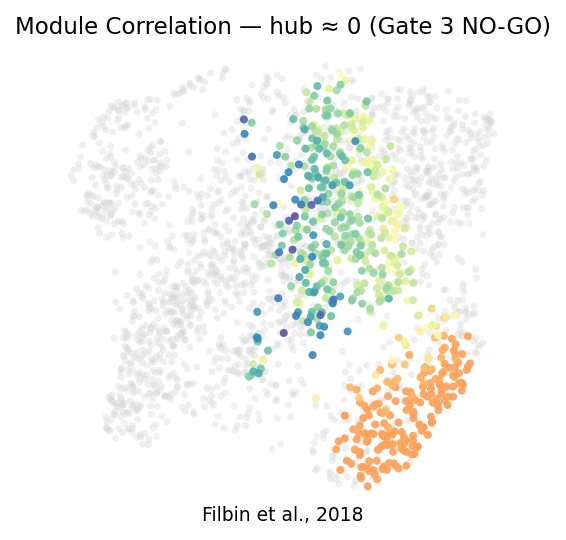

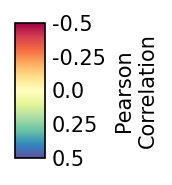

In [8]:
# hub = non-cycling early-pseudotime convergence zone (windowing domain, cycling excluded)
hub = (t <= np.quantile(t, 0.40)) & (adata.obs['cyc_score'].values < 0.1)
g = pd.merge(gast_ser, psom_ser, 'outer').hsapiens.drop_duplicates(); g = g.loc[g.isin(adata.var_names)]
adata_corr = adata[hub, g.values].copy()
adata_corr.obs['GSE162534'] = adata.obs.loc[hub, 'Gast'].values
adata_corr.obs['GSE229103'] = adata.obs.loc[hub, 'pSom'].values
n_cells = 60; th = adata_corr.obs.t; n_bins = max(2, th.size // n_cells)
t_bin = pd.cut(th, bins=n_bins); adata_corr.obs['t_bin'] = t_bin
r_dict = {}
for b, sdf in adata_corr.obs.groupby('t_bin', observed=True):
    ab = adata_corr[sdf.index].copy()
    X = pd.DataFrame(ab.X.toarray(), index=sdf.index, columns=g.values); X = X.loc[:, (X.nunique(0)>1)]
    if X.shape[1] < 3 or X.shape[0] < 5: continue
    a = pearsonr(X, sdf.GSE162534.values[:,None], axis=0).statistic
    bb = pearsonr(X, sdf.GSE229103.values[:,None], axis=0).statistic
    r_dict[b] = float(np.corrcoef(a, bb)[0,1])
A = adata_corr.obsp['connectivities']; Rv = t_bin.map(r_dict).astype(float)
den = np.asarray(A.sum(1)).ravel(); den[den==0] = 1
adata_corr.obs['correlation'] = np.asarray(A @ Rv.fillna(np.nanmean(Rv)).values).ravel() / den
print('windowed r by pseudotime bin:', {str(k): round(v,3) for k,v in r_dict.items()})
vlim = .5
fig, ax = plt.subplots(figsize=(4, 4))
sc.pl.umap(adata, size=45, alpha=.35, frameon=False, show=False, ax=ax)
sc.pl.umap(adata_corr, color='correlation', cmap='Spectral', vmin=-vlim, vmax=vlim, size=60, alpha=.9,
           colorbar_loc=None, frameon=False, show=False, ax=ax)
ax.set_title('Module Correlation — hub ≈ 0 (Gate 3 NO-GO)', size=11)
ax.text(.5, -.03, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=9)
fig.savefig(os.path.join(pth_fig, 'correlation.pdf'), bbox_inches='tight'); plt.show()
fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(ax.collections[1], cax=cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Pearson\nCorrelation'); cb.ax.invert_yaxis()
ticks = np.asarray([-.5,-.25,0,.25,.5]); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
fcb.savefig(os.path.join(pth_cb, 'R_colorbar.pdf'), bbox_inches='tight'); plt.show()
print('saved correlation.pdf + colorbars/R_colorbar.pdf')